In [2]:
!pip install -q yfinance

In [4]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA

In [8]:
ticker = 'TSLA'

df = yf.download(
    ticker,
    start='2023-01-01',
    auto_adjust=True,
    multi_level_index=False,
    progress=False
)

# select closing prices
ts = df['Close'].dropna()

print(ts.head())
print(ts.tail())

Date
2023-01-03    108.099998
2023-01-04    113.639999
2023-01-05    110.339996
2023-01-06    113.059998
2023-01-09    119.769997
Name: Close, dtype: float64
Date
2026-11-04    385.190002
2026-11-05    343.690002
2026-11-06    358.220001
2026-11-09    378.049988
2026-11-10    379.779999
Name: Close, dtype: float64


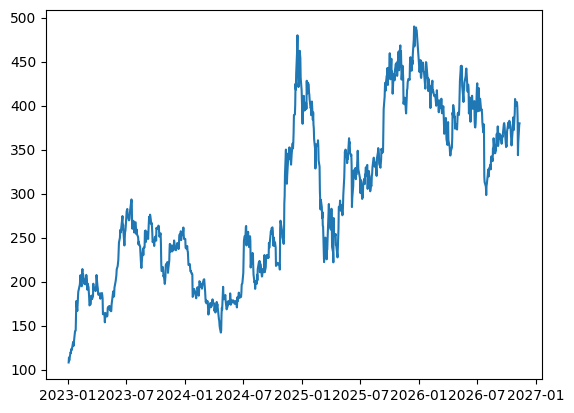

In [9]:
plt.plot(ts)

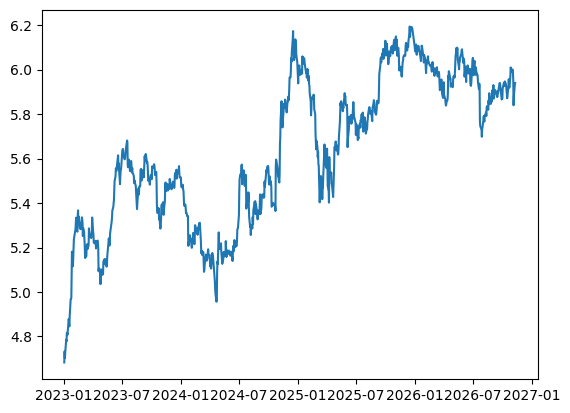

In [11]:
# get the log to shrink the flacuations

ts_log = np.log(ts)

plt.plot(ts_log)

In [12]:
train = ts.iloc[:-60]
test = ts.iloc[-60:]

log_train = np.log(train)

model = ARIMA(log_train.values, order=(1, 1, 1))

In [13]:
model_fit = model.fit()

forecast_log = model_fit.forecast(steps=len(test))